# BERT sentence-pair classification

Fine-tunes `bert-base-uncased` on (review, aspect) pairs. The learning rate is chosen on the validation split, the weights of the best epoch are kept, and the official test file is scored once. Training uses bfloat16 on the GPU and takes a few minutes per domain on an A100.

## Setup

Run this on a Colab GPU runtime (*Runtime → Change runtime type → GPU*). The cell clones the repository, installs the dependencies and checks the environment. Colab keeps its own `torch`, so it is left as it is.

In [1]:
import os

if not os.path.isdir("aspect-based-sentiment-analysis"):
    !git clone -q https://github.com/Shivam-Shukla0/aspect-based-sentiment-analysis.git
%cd aspect-based-sentiment-analysis
!pip install -q -r requirements.txt
!pip install -q -e . --no-deps
!python -m scripts.verify_environment --require-gpu

/content/run/aspect-based-sentiment-analysis


  Installing build dependencies ... done


  Checking if build backend supports build_editable ... done


  Getting requirements to build editable ... done


  Preparing editable metadata (pyproject.toml) ... done


  Building editable for absa (pyproject.toml) ... done


python          3.13.16
numpy           2.4.6
pandas          2.2.3
scikit-learn    1.6.1
lxml            6.1.3
torch           2.14.1+cu130
transformers    5.22.1
accelerate      1.15.0
sentencepiece   0.2.2
matplotlib      3.10.0
flask           3.1.3
absa            0.1.0
device          NVIDIA L4 (CUDA 13.0, 1 device)
environment ok


## Data

The official SemEval-2014 Task 4 files are distributed through the ILSP Metashare repository and need an account and acceptance of its licence (see `data/README.md`). This cell uses those files when they are in Google Drive (set `USE_DRIVE = True` after mounting Drive), and otherwise downloads the same four files from a public Hugging Face mirror of the dataset. The mirror did not come through the official route, so the file checksums are printed and the report states this limitation. Nothing in `data/` is committed to Git.

In [2]:
from pathlib import Path

USE_DRIVE = False  # True: copy the official files from DRIVE_DIR (mount Drive first)
DRIVE_DIR = Path("/content/drive/MyDrive/absa/semeval2014")
MIRROR = "https://huggingface.co/datasets/alexcadillon/SemEval2014Task4/resolve/main"
TRAIN = "SemEval%2714-ABSA-TrainData_v2%20%26%20AnnotationGuidelines"
FILES = {
    "Laptop_Train_v2.xml": (f"{MIRROR}/{TRAIN}/Laptop_Train_v2.xml", "laptop", "train"),
    "Restaurants_Train_v2.xml": (f"{MIRROR}/{TRAIN}/Restaurants_Train_v2.xml", "restaurant", "train"),
    "Laptops_Test_Gold.xml": (f"{MIRROR}/ABSA_Gold_TestData/Laptops_Test_Gold.xml", "laptop", "test"),
    "Restaurants_Test_Gold.xml": (
        f"{MIRROR}/ABSA_Gold_TestData/Restaurants_Test_Gold.xml",
        "restaurant",
        "test",
    ),
}
Path("data/raw").mkdir(parents=True, exist_ok=True)
for name, (url, domain, split) in FILES.items():
    if USE_DRIVE:
        !cp "{DRIVE_DIR / name}" data/raw/
    else:
        !curl -sL -o data/raw/{name} "{url}"
    !python -m scripts.build_processed data/raw/{name} --domain {domain} --split {split} > /dev/null
!sha256sum data/raw/*.xml
!wc -l data/processed/*.jsonl

aa3a30c9dd7e0eacf9b69e898eb4118a36c1b4f391a30a08dfc41a38d8b8745b  data/raw/Laptops_Test_Gold.xml
efec2ed73b4efb83b47c697114d800149c558118884afa80362a6e975ba7248c  data/raw/Laptop_Train_v2.xml
f21509cfa37e16534cd5b2da043be487355b64ef48fe8d6aaacaeca6b49cc0fb  data/raw/Restaurants_Test_Gold.xml
223601da1bded6caa4ef9cf91a7007578141ca6d8ed50d5a5c217565f89d2fc5  data/raw/Restaurants_Train_v2.xml


    654 data/processed/laptop_test.jsonl
    378 data/processed/laptop_test_no_aspect.jsonl
   2358 data/processed/laptop_train.jsonl
   1557 data/processed/laptop_train_no_aspect.jsonl
   1134 data/processed/restaurant_test.jsonl
    194 data/processed/restaurant_test_no_aspect.jsonl
   3693 data/processed/restaurant_train.jsonl
   1020 data/processed/restaurant_train_no_aspect.jsonl
  10988 total


## Fine-tune and evaluate

In [3]:
for domain in ("laptop", "restaurant"):
    !python -m scripts.train_bert --domain {domain} --output-dir outputs/bert_{domain} 2>&1 | grep -E "^(run|laptop|restaurant)"

run 0: lr 2e-05 val macro F1 0.7028


run 1: lr 3e-05 val macro F1 0.7161


run 2: lr 5e-05 val macro F1 0.7226


laptop: chosen lr=5e-05; test accuracy 0.7586 macro F1 0.6977


run 0: lr 2e-05 val macro F1 0.6942


run 1: lr 3e-05 val macro F1 0.6924


run 2: lr 5e-05 val macro F1 0.7169


restaurant: chosen lr=5e-05; test accuracy 0.8286 macro F1 0.7295


## Results

In [4]:
import json

import pandas as pd

rows = []
for domain in ("laptop", "restaurant"):
    summary = json.load(open(f"outputs/bert_{domain}/summary.json"))
    report = json.load(open(f"outputs/bert_{domain}/test_report.json"))
    print(domain, "- validation macro F1 per setting:")
    for run in summary["runs"]:
        print("   ", {k: v for k, v in run.items() if k != "config"} | {k: run["config"][k] for k in ("hidden_size", "learning_rate", "dropout") if "config" in run})
    for cls in report["metrics"]["per_class"]:
        rows.append({"domain": domain, **{k: cls[k] for k in ("label", "precision", "recall", "f1", "support")}})
    print(f"   TEST accuracy {summary['test_accuracy']:.3f}  macro F1 {summary['test_macro_f1']:.3f}  ({summary['test_records']} records)")
pd.DataFrame(rows).round(3)

laptop - validation macro F1 per setting:
    {'learning_rate': 2e-05, 'best_epoch': 3, 'val_macro_f1': 0.7027730806443154}
    {'learning_rate': 3e-05, 'best_epoch': 4, 'val_macro_f1': 0.7161265494929371}
    {'learning_rate': 5e-05, 'best_epoch': 4, 'val_macro_f1': 0.722611843082912}
   TEST accuracy 0.759  macro F1 0.698  (638 records)
restaurant - validation macro F1 per setting:
    {'learning_rate': 2e-05, 'best_epoch': 4, 'val_macro_f1': 0.6941851697569481}
    {'learning_rate': 3e-05, 'best_epoch': 4, 'val_macro_f1': 0.6923773832478815}
    {'learning_rate': 5e-05, 'best_epoch': 4, 'val_macro_f1': 0.7169283901202411}
   TEST accuracy 0.829  macro F1 0.729  (1120 records)


,domain,label,precision,recall,f1,support
0,laptop,positive,0.855,0.900,0.877,341
1,laptop,negative,0.597,0.844,0.699,128
2,laptop,neutral,0.704,0.408,0.517,169
3,restaurant,positive,0.869,0.953,0.909,728
4,restaurant,negative,0.756,0.791,0.773,196
5,restaurant,neutral,0.681,0.403,0.506,196


## Confusion matrices

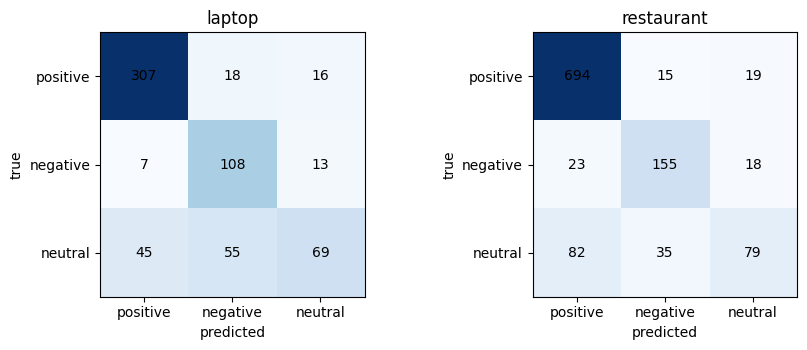

In [5]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, domain in zip(axes, ("laptop", "restaurant")):
    report = json.load(open(f"outputs/bert_{domain}/test_report.json"))
    matrix = np.array(report["confusion_matrix"])
    ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(len(report["labels"])), report["labels"])
    ax.set_yticks(range(len(report["labels"])), report["labels"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(domain)
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, int(value), ha="center", va="center")
plt.tight_layout()
plt.show()

## Where the errors are

Counts of (true → predicted) pairs, which show which polarities the model confuses.

In [6]:
for domain in ("laptop", "restaurant"):
    errors = json.load(open(f"outputs/bert_{domain}/test_report.json"))["errors"]
    print(domain, errors["total_errors"], "errors")
    for pair, count in sorted(errors["counts_by_pair"].items(), key=lambda kv: -kv[1]):
        print(f"   {pair:24s} {count}")

laptop 154 errors
   neutral->negative        55
   neutral->positive        45
   positive->negative       18
   positive->neutral        16
   negative->neutral        13
   negative->positive       7
restaurant 192 errors
   neutral->positive        82
   neutral->negative        35
   negative->positive       23
   positive->neutral        19
   negative->neutral        18
   positive->negative       15
